# Análisis Exploratorio de Datos y Limpieza

In [2]:
from scipy import stats
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## Análisis Exploratorio de Datos.
Antes de cosntruir los modelos, vamos a realizar un análisis acerca de como esta formado el nuevo dataset, ver que variables son más relevantes, ver valores atípicos, etc.

In [6]:
target = 'rendimiento_t_ha'
df = pd.read_csv('../Dataset/NewDataset/dataset_modelo_cebada.csv').copy()

train = df[df['CONJUNTO'] == 'ENTRENAMIENTO'].copy()
test = df[df['CONJUNTO'] == 'PREDICCION'].copy()


In [5]:
def features_group(c):
    if 'n_validos' in c: return 'calidad_satelital'
    if c.startswith('s2'): return 'satelital_s2'
    if c.startswith('pl_'): return 'satelital_planet'
    if c.startswith('ls_'): return 'satelital_landsat'
    if c.startswith(("precipitacion", "Tmax", "Tmin", "amplitud")): return 'clima'
    if c.startswith(("elevacion", "pendiente", "cobertura")): return 'topografia'
    return 'otro'

In [6]:
features = [c for c in df.select_dtypes('number').columns if c != target]
groups = pd.Series({c: features_group(c) for c in features})

print("Entrenamiento:", train.shape, "| Predicción:", test.shape)
print(groups.value_counts())
print("Sin grupo asignado:", groups[groups == "otro"].index.tolist())

Entrenamiento: (138, 103) | Predicción: (59, 103)
satelital_s2         32
satelital_planet     27
clima                12
satelital_landsat    12
calidad_satelital    10
topografia            5
otro                  1
Name: count, dtype: int64
Sin grupo asignado: ['área_ha']


### Calidad de los datos.
Vemos si hay valores faltantes.

In [10]:
summary = pd.DataFrame({
    'grupo': groups,
    'valores_faltantes_pct': df[features].isna().mean() * 100,
    'n_unicos': df[features].nunique(),
    'cv': df[features].std() / df[features].mean().abs(), #Coeficiente de vaaizon
})

print(summary.groupby("grupo")["valores_faltantes_pct"].agg(["count", "mean", "max"]).round(1))
print("\nVariables con más faltantes:")
print(summary.sort_values("valores_faltantes_pct", ascending=False).head(10).round(1))
print("\nConstantes:", summary[summary["n_unicos"] <= 1].index.tolist())
print("Casi constantes (CV < 1 %):", summary[summary["cv"] < 0.01].index.tolist())

                   count  mean  max
grupo                              
calidad_satelital     10   0.0  0.0
clima                 12   0.0  0.0
otro                   1   0.0  0.0
satelital_landsat     12   0.3  2.5
satelital_planet      27   0.0  0.0
satelital_s2          32   0.0  0.0
topografia             5   0.0  0.0

Variables con más faltantes:
                                                   grupo  \
ls_vi6t_mes_09                         satelital_landsat   
ls_vi6t_mes_07                         satelital_landsat   
precipitacion_acumulada_abril_octubre              clima   
Tmax_media_abril_octubre                           clima   
Tmax_media_anual                                   clima   
Tmax_media_mayo_octubre                            clima   
Tmin_media_abril_octubre                           clima   
Tmin_media_anual                                   clima   
Tmin_media_mayo_octubre                            clima   
amplitud_termica_media_abril_octubre          

Hay muy pocos valores faltantes, el que mayor tiene e vi6t del mes 9 con 2.5%  y vi5t del mes 7 de valores faltantes. Es decir entre 5 a tres parcelas.

In [11]:
print(df[["Tmax_media_anual", "Tmax_media_abril_octubre", "Tmax_media_mayo_octubre"]].std().round(3))

Tmax_media_anual            0.120
Tmax_media_abril_octubre    0.156
Tmax_media_mayo_octubre     0.172
dtype: float64


### Análisis de Variable objetivo.

count    138.00
mean       3.96
std        0.85
min        2.00
25%        3.20
50%        4.34
75%        4.55
max        5.59
Name: rendimiento_t_ha, dtype: float64
Asimetría:  -0.33


C:\Users\gonzo\AppData\Local\Temp\ipykernel_21372\3389406765.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(y, vert=False)


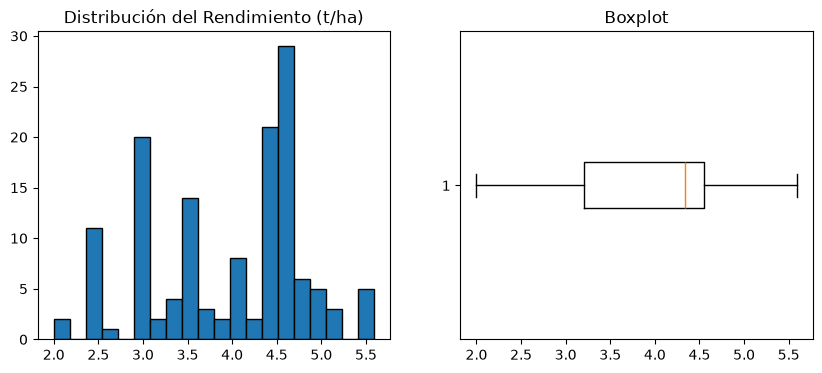

Valores atípicos: 0
Empty DataFrame
Columns: [ID_POLIGON, Municipio, área_ha, rendimiento_t_ha]
Index: []


In [16]:
y = train[target]

print(y.describe().round(2))
print('Asimetría: ', round(y.skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(y, bins=20, edgecolor="k")
ax[0].set_title('Distribución del Rendimiento (t/ha)')

ax[1].boxplot(y, vert=False)
ax[1].set_title('Boxplot')
plt.show()

q1, q3 = y.quantile([.25, 0.75])
iqr = q3 - q1
atipicos = train[(y < q1 - 1.5 *iqr) | (y > q3 + 1.5 * iqr)]

print(f'Valores atípicos: {len(atipicos)}')
print(atipicos[['ID_POLIGON', 'Municipio', 'área_ha', target]]) 


### Análisis de variables de entrenamiento vs los datos para predicción

Vamos a utilizar una correlación de Spearman, utilizamos esta por que no considera una distribución de datos normal.

                               count  mean   std   min   max
Municipio                                                   
Almoloya                          10  4.52  0.19  4.14  4.87
Apan                               1  3.00   NaN  3.00  3.00
Calpulalpan                       30  3.00  0.37  2.50  3.50
Chignahuapan                      71  4.48  0.58  2.15  5.59
Cuautepec de Hinojosa              5  4.60  0.15  4.40  4.79
Emiliano Zapata                    3  3.50  0.00  3.50  3.50
Nanacamilpa de Mariano Arista      1  2.50   NaN  2.50  2.50
Singuilucan                       16  3.08  0.43  2.00  3.70
Tepeapulco                         1  4.45   NaN  4.45  4.45
Spearman - Área_ha vs Rendimiento: rho: -0.249, p=0.00321


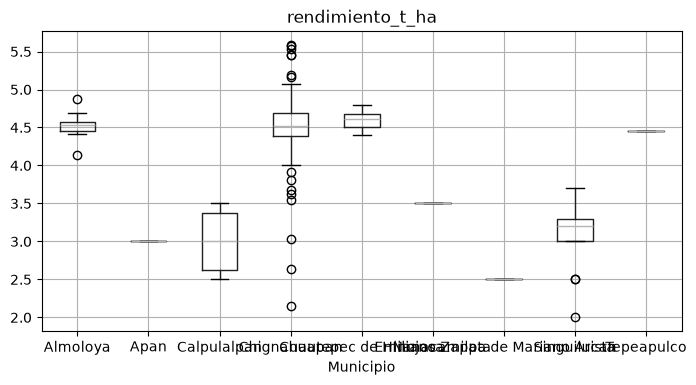

In [17]:
print(train.groupby('Municipio')[target].agg(['count', 'mean', 'std', 'min', 'max']).round(2))

rho, p = stats.spearmanr(train['área_ha'], y)

print(f'Spearman - Área_ha vs Rendimiento: rho: {rho:.3f}, p={p:.3g}')

train.boxplot(column=target, by='Municipio', figsize=(8, 4))
plt.suptitle('')
plt.show()

Chignahuapan tiene una caja muy estrecha (alrededor de 4.4 a 4.7) y muchos puntos fuera por ambos lados: bajos desde 2.15 hasta 3.9 y altos de 5.2 a 5.6. Esas colas son donde un modelo tendría que aportar algo. Calpulalpan y Singuilucan viven en escalones de 2.5, 3.0 y 3.5.

### Análisis de variables de entrenamiento vs predicción.

Vamos a utilizar la  prueba de Kolmogorov-Smirnov para ver si dos conjuntos de datos son idénticos, en este caso comparamos los datos de entrenamiento con los de prueba.

In [19]:
print(pd.crosstab(df['CONJUNTO'], df['Municipio'], normalize='index').round(2))

filas = []
for c in features:
    a, b = train[c].dropna(), test[c].dropna()
    
    if len(a) > 5 and len(b) > 5:
        ks = stats.ks_2samp(a, b) #Prueba de Kolmogorov-Smirnov
        filas.append((c, groups[c], ks.statistic, ks.pvalue))

shift = pd.DataFrame(filas, columns=['variables', 'grupo', 'ks', 'p']).sort_values('ks', ascending=False)

print("\nVariables más distintas entre entrenamiento y predicción:")
print(shift.head(10).round(3))
print(f"\nCon p < 0.01: {(shift['p'] < 0.01).sum()} de {len(shift)}  (por azar se esperaría ~1 %)")

Municipio      Almoloya  Apan  Calpulalpan  Chignahuapan  \
CONJUNTO                                                   
ENTRENAMIENTO      0.07  0.01         0.22          0.51   
PREDICCION         0.07  0.00         0.24          0.49   

Municipio      Cuautepec de Hinojosa  Emiliano Zapata  \
CONJUNTO                                                
ENTRENAMIENTO                   0.04             0.02   
PREDICCION                      0.07             0.00   

Municipio      Nanacamilpa de Mariano Arista  Singuilucan  Tepeapulco  
CONJUNTO                                                               
ENTRENAMIENTO                           0.01         0.12        0.01  
PREDICCION                              0.02         0.12        0.00  

Variables más distintas entre entrenamiento y predicción:
                                variables             grupo     ks      p
46                         s2_msi_doy_max      satelital_s2  0.273  0.003
80                         pl_ndvi_

### Variables y Rendimiento.


In [23]:
def tabla_spearman(df, cols):
    filas = []
    
    for col in cols:
        s = df[[col, target]].dropna()
        
        if len(s) > 10 and s[col].nunique() > 1:
            r, p = stats.spearmanr(s[col], s[target])
            filas.append((col, groups[col], len(s), r, p))
    
    t = pd.DataFrame(filas, columns=['variable', 'grupo', 'n', 'rho', 'p'])
    t = t.sort_values('p').reset_index(drop=True)
    m = len(t)
    
    t["q_bh"] = (t["p"] * m / (t.index + 1)).iloc[::-1].cummin().iloc[::-1].clip(upper=1)
    return t.sort_values("rho", key=abs, ascending=False).reset_index(drop=True)
    

In [24]:
tabla = tabla_spearman(train, features)
print(tabla.head(15).round(3))
print("\nMejores 3 por grupo:")
print(tabla.groupby("grupo").head(3).sort_values(["grupo", "rho"], key=lambda s: s.abs() if s.name == "rho" else s).round(3))
print(f"\nVariables con q_BH < 0.10: {(tabla['q_bh'] < 0.10).sum()} de {len(tabla)}")

                                variable              grupo    n    rho    p  \
0                       Tmin_media_anual              clima  138  0.675  0.0   
1           amplitud_termica_media_anual              clima  138 -0.674  0.0   
2   amplitud_termica_media_abril_octubre              clima  138 -0.669  0.0   
3    amplitud_termica_media_mayo_octubre              clima  138 -0.665  0.0   
4                      ls_vi6t_n_validos  calidad_satelital  138  0.574  0.0   
5                         s2_ndvi_mes_05       satelital_s2  138  0.570  0.0   
6               Tmin_media_abril_octubre              clima  138  0.542  0.0   
7                Tmin_media_mayo_octubre              clima  138  0.504  0.0   
8                         s2_ndvi_mes_06       satelital_s2  138  0.502  0.0   
9                         pl_ndvi_mes_05   satelital_planet  138  0.427  0.0   
10                      s2_lai_n_validos  calidad_satelital  138 -0.406  0.0   
11                     s2_ndwi_n_validos

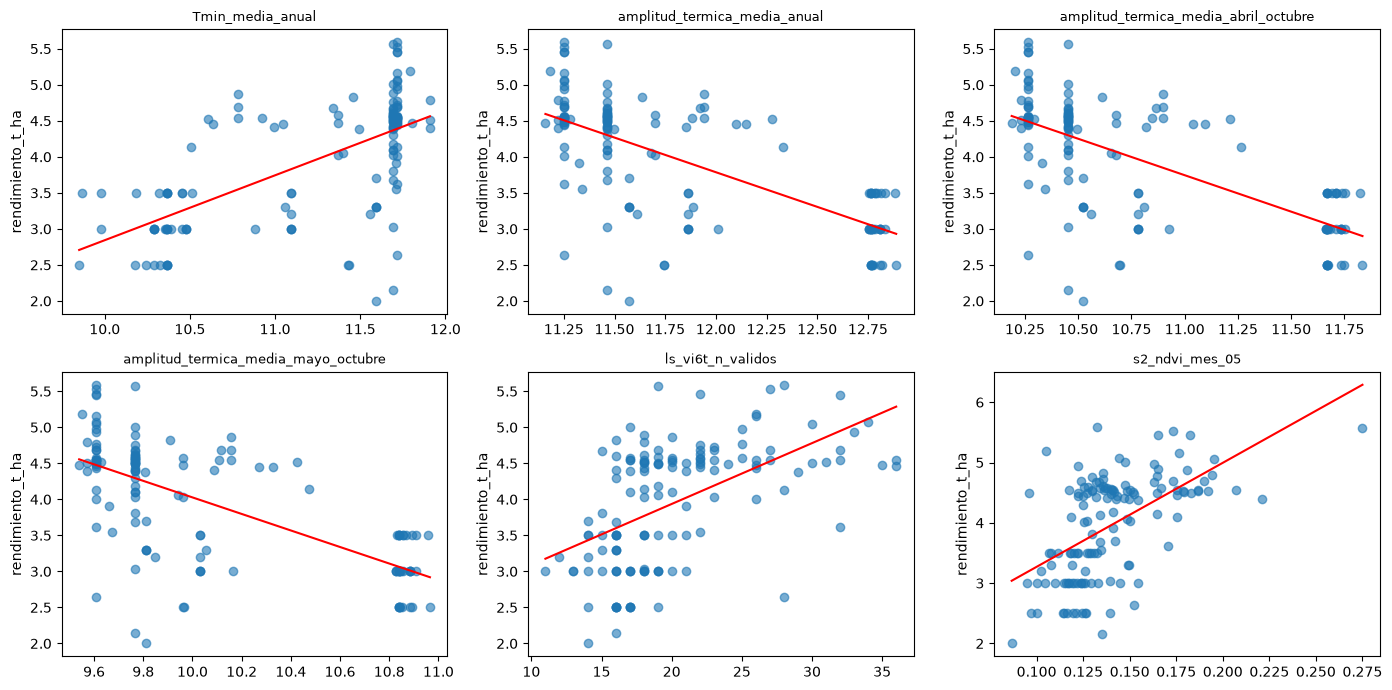

In [26]:
top = tabla.head(6)["variable"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), top):
    s = train[[c, target]].dropna()
    ax.scatter(s[c], s[target], alpha=.6)
    k = np.polyfit(s[c], s[target], 1); xs = np.linspace(s[c].min(), s[c].max(), 50)
    ax.plot(xs, np.polyval(k, xs), "r-")
    ax.set_title(c, fontsize=9); ax.set_ylabel(target)
plt.tight_layout(); plt.show()

### Redundancia de Variables

Pares con |rho| > 0.95: 26 de 7921
cobertura_elevacion_pct                cobertura_pendiente_pct                 1.000
precipitacion_acumulada_abril_octubre  precipitacion_acumulada_mayo_octubre    1.000
amplitud_termica_media_abril_octubre   amplitud_termica_media_mayo_octubre     0.998
precipitacion_acumulada_anual          precipitacion_acumulada_mayo_octubre    0.997
precipitacion_acumulada_abril_octubre  precipitacion_acumulada_anual           0.997
amplitud_termica_media_anual           amplitud_termica_media_mayo_octubre     0.997
Tmin_media_anual                       amplitud_termica_media_anual           -0.997
amplitud_termica_media_abril_octubre   amplitud_termica_media_anual            0.996
Tmin_media_abril_octubre               Tmin_media_mayo_octubre                 0.995
pl_evi_std                             pl_msavi_std                            0.995
Tmin_media_anual                       amplitud_termica_media_mayo_octubre    -0.994
                              

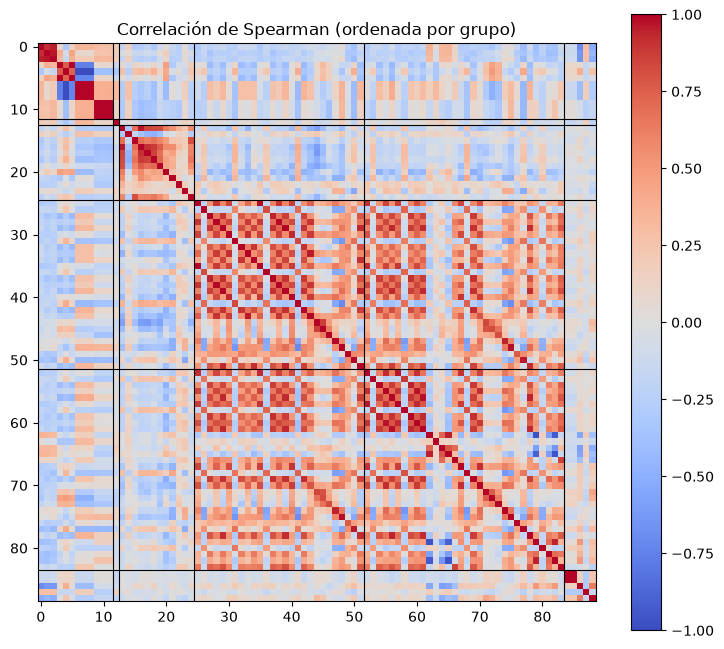

In [28]:
cols = [c for c in features if groups[c] != "calidad_satelital" and train[c].nunique() > 1]
cols = sorted(cols, key=lambda c: (groups[c], c))
corr = train[cols].corr(method="spearman")

pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
alta = pares[pares.abs() > 0.95].sort_values(key=abs, ascending=False)
print(f"Pares con |rho| > 0.95: {len(alta)} de {len(pares)}")
print(alta.head(15).round(3))

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
lim = np.cumsum(groups[cols].value_counts(sort=False).reindex(pd.unique(groups[cols])).values)
for l in lim[:-1]: ax.axhline(l - .5, c="k", lw=.8); ax.axvline(l - .5, c="k", lw=.8)
ax.set_title("Correlación de Spearman (ordenada por grupo)"); fig.colorbar(im); plt.show()

### Análisis por municipio y parcela.
el rendimiento cambia mucho entre municipios (Calpulalpan y Singuilucan ≈ 3.0 t/ha; Chignahuapan, Almoloya y Cuautepec ≈ 4.5). Muchas variables pueden correlacionar solo por *dónde* está la parcela. Aquí se mide cuánto es región y cuánto es señal dentro de la región.

In [30]:
def cv_baseline(d, por="Municipio", k=5, reps=30, seed=0):
    #Predice con la media global vs la media del municipio (calculada solo con el pliegue de entrenamiento)
    rng = np.random.default_rng(seed)
    y = d[target].to_numpy()
    rmse_g, rmse_m = [], []
    for _ in range(reps):
        idx = rng.permutation(len(d))
        p_g, p_m = np.empty(len(d)), np.empty(len(a))
        for f in np.array_split(idx, k):
            tr = np.setdiff1d(idx, f)
            mg = y[tr].mean()
            medias = d.iloc[tr].groupby(por)[target].mean()
            p_g[f] = mg
            p_m[f] = d.iloc[f][por].map(medias).fillna(mg).to_numpy()
        rmse_g.append(np.sqrt(((y - p_g) ** 2).mean()))
        rmse_m.append(np.sqrt(((y - p_m) ** 2).mean()))
    rg, rm = np.mean(rmse_g), np.mean(rmse_m)
    print(f"RMSE con la media global:        {rg:.3f} t/ha")
    print(f"RMSE con la media del municipio: {rm:.3f} t/ha")
    print(f"R² aproximado del 'modelo municipio': {1 - (rm / rg) ** 2:.2f}")

cv_baseline(train)

RMSE con la media global:        0.855 t/ha
RMSE con la media del municipio: 0.513 t/ha
R² aproximado del 'modelo municipio': 0.64


Correalciones en el municipio.

In [33]:
# Se quita el promedio de cada municipio (solo municipios con >= 5 parcelas) y se correlaciona lo que sobra
grande = train.groupby("Municipio")[target].transform("size") >= 5
d = train[grande].copy()
cols = [c for c in features if groups[c] != "calidad_satelital" and d[c].nunique() > 1]
dm = d[cols + [target]] - d.groupby("Municipio")[cols + [target]].transform("mean")

print("Municipios usados:", d["Municipio"].value_counts().to_dict(), "| n =", len(d))

dentro = tabla_spearman(dm, cols).rename(columns={"rho": "rho_dentro", "p": "p_dentro", "q_bh": "q_dentro"})
global_ = tabla_spearman(train, cols)[["variable", "rho"]].rename(columns={"rho": "rho_global"})
comp = dentro.merge(global_, on="variable")
print(comp.head(20)[["variable", "grupo", "rho_global", "rho_dentro", "p_dentro", "q_dentro"]].round(3))
print(f"\nq < 0.10 dentro del municipio: {(comp['q_dentro'] < 0.10).sum()} de {len(comp)}  (globalmente eran 65 de 99)")

print("\nCambio por grupo (mediana de |rho|):")
comp["abs_global"] = comp["rho_global"].abs(); comp["abs_dentro"] = comp["rho_dentro"].abs()
print(comp.groupby("grupo")[["abs_global", "abs_dentro"]].median().round(2))

Municipios usados: {'Chignahuapan': 71, 'Calpulalpan': 30, 'Singuilucan': 16, 'Almoloya': 10, 'Cuautepec de Hinojosa': 5} | n = 132
                                variable             grupo  rho_global  \
0                        s2_ndwi_doy_max      satelital_s2       0.097   
1                        pendiente_media        topografia       0.232   
2                         s2_ndvi_mes_09      satelital_s2      -0.050   
3                         s2_ndvi_mes_04      satelital_s2       0.369   
4                         pl_ndvi_mes_04  satelital_planet       0.199   
5                        pl_ndvi_doy_max  satelital_planet       0.274   
6                         pl_ndvi_mes_05  satelital_planet       0.427   
7                         s2_ndvi_mes_10      satelital_s2       0.360   
8                         s2_ndvi_mes_07      satelital_s2      -0.009   
9           amplitud_termica_media_anual             clima      -0.674   
10                        s2_ndvi_mes_05      satelita

In [ ]:
#VAlores aitpicos
g = train.groupby("Municipio")[target]
z = (train[target] - g.transform("mean")) / g.transform("std")
raros = train.loc[(z.abs() > 2.5) & (g.transform("size") >= 10),
                  ["ID_POLIGON", "Municipio", "área_ha", target]].assign(z=z)
print(raros.sort_values("z").round(2))

    ID_POLIGON     Municipio  área_ha  rendimiento_t_ha     z
170    AGC_171  Chignahuapan    11.63              2.15 -3.98
14     AGC_015  Chignahuapan     1.97              2.64 -3.14


In [36]:
y = train[target].to_numpy()
medio = np.isclose(y * 2, np.round(y * 2), atol=1e-6)   # múltiplo exacto de 0.5 t/ha
print(f"Parcelas con rendimiento múltiplo exacto de 0.5 t/ha: {medio.mean() * 100:.0f} %")
print(train.assign(multiplo_05=medio).groupby("Municipio")["multiplo_05"].agg(["size", "mean"]).round(2))
print("\nValores más repetidos:")
print(train[target].round(2).value_counts().head(10))

Parcelas con rendimiento múltiplo exacto de 0.5 t/ha: 33 %
                               size  mean
Municipio                                
Almoloya                         10  0.00
Apan                              1  1.00
Calpulalpan                      30  1.00
Chignahuapan                     71  0.01
Cuautepec de Hinojosa             5  0.00
Emiliano Zapata                   3  1.00
Nanacamilpa de Mariano Arista     1  1.00
Singuilucan                      16  0.56
Tepeapulco                        1  0.00

Valores más repetidos:
rendimiento_t_ha
3.00    19
3.50    13
2.50    11
4.55     5
4.52     5
4.49     4
3.30     4
4.54     4
4.69     3
4.51     3
Name: count, dtype: int64


Chianauaapm:


In [38]:
ch = train[train["Municipio"] == "Chignahuapan"].copy()
n = len(ch)
tcrit = stats.t.ppf(0.975, n - 2)
print(f"n = {n} | |rho| mínimo para p < 0.05 sin corregir: {tcrit / np.sqrt(n - 2 + tcrit ** 2):.2f}")
print(f"Rendimiento: media {ch[target].mean():.2f}, std {ch[target].std():.2f}, "
      f"rango {ch[target].min():.2f} - {ch[target].max():.2f}")

print("\nValores distintos de Tmin_media_anual en Chignahuapan:", ch["Tmin_media_anual"].nunique())
print(ch["Tmin_media_anual"].round(2).value_counts().head(4))

cols_ch = [c for c in features if groups[c] != "calidad_satelital" and ch[c].nunique() > 1]
t_ch = tabla_spearman(ch, cols_ch)
print("\nTop 15 dentro de Chignahuapan:")
print(t_ch.head(15)[["variable", "grupo", "n", "rho", "p", "q_bh"]].round(3))
print(f"\nq < 0.10: {(t_ch['q_bh'] < 0.10).sum()} de {len(t_ch)}")

n = 71 | |rho| mínimo para p < 0.05 sin corregir: 0.23
Rendimiento: media 4.48, std 0.58, rango 2.15 - 5.59

Valores distintos de Tmin_media_anual en Chignahuapan: 11
Tmin_media_anual
11.69    33
11.72    29
11.71     3
11.46     1
Name: count, dtype: int64

Top 15 dentro de Chignahuapan:
                                 variable             grupo   n    rho      p  \
0                         pendiente_media        topografia  71  0.311  0.008   
1                        Tmin_media_anual             clima  71  0.284  0.016   
2            amplitud_termica_media_anual             clima  71 -0.284  0.016   
3    amplitud_termica_media_abril_octubre             clima  71 -0.283  0.017   
4                          s2_ndvi_mes_04      satelital_s2  71  0.276  0.020   
5                                 área_ha              otro  71 -0.271  0.022   
6     amplitud_termica_media_mayo_octubre             clima  71 -0.256  0.031   
7           precipitacion_acumulada_anual             clima  7

       count   min   max
nivel                   
bajo      24  2.15  4.46
medio     23  4.47  4.57
alto      24  4.59  5.59


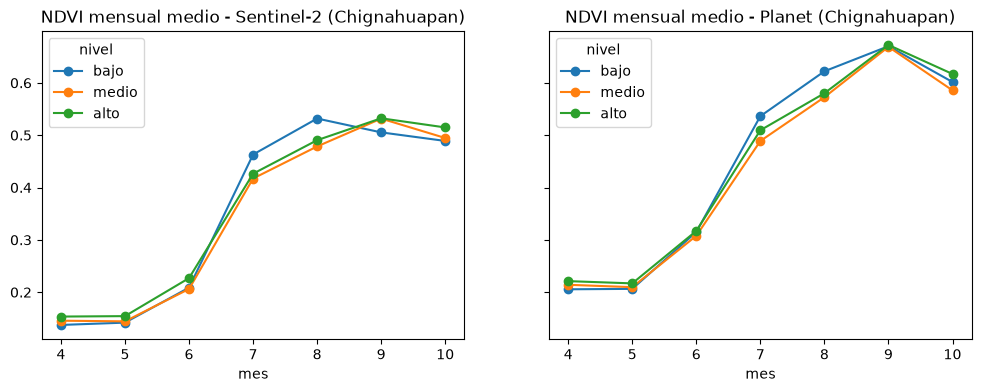

       s2_ndvi_doy_max_mean  s2_ndvi_doy_max_std
nivel                                           
bajo                239.208               25.514
medio               245.913               20.336
alto                251.042               28.129
       s2_ndvi_max_mean  s2_ndvi_max_std
nivel                                   
bajo              0.640            0.074
medio             0.637            0.065
alto              0.643            0.071
       s2_ndvi_auc_mean  s2_ndvi_auc_std
nivel                                   
bajo              0.366            0.036
medio             0.358            0.032
alto              0.369            0.041


In [39]:
ch["nivel"] = pd.qcut(ch[target], 3, labels=["bajo", "medio", "alto"])
print(ch.groupby("nivel", observed=True)[target].agg(["count", "min", "max"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, pref, nombre in zip(axes, ["s2", "pl"], ["Sentinel-2", "Planet"]):
    cm = sorted(c for c in ch.columns if c.startswith(f"{pref}_ndvi_mes_"))
    if not cm:
        continue
    curvas = ch.groupby("nivel", observed=True)[cm].mean().T
    curvas.index = [int(c[-2:]) for c in curvas.index]
    curvas.plot(ax=ax, marker="o"); ax.set_title(f"NDVI mensual medio - {nombre} (Chignahuapan)")
    ax.set_xlabel("mes")
plt.show()

for c in ["s2_ndvi_doy_max", "s2_ndvi_max", "s2_ndvi_auc"]:
    if c in ch:
        print(ch.groupby("nivel", observed=True)[c].agg(["mean", "std"]).round(3).add_prefix(c + "_"))

### Buscar relación entre rendimiento y zona.


In [40]:
import geopandas as gpd
from scipy.spatial import cKDTree

# Ajusta la ruta relativa a ESTE notebook (es el mismo shapefile de extract_data.ipynb)
RUTA_SHP = "../../DataSet/DATASET_RETO_AGRO_2026/Parcelas_Reto_AGC_CONJUNTO_70_30/Parcelas_Reto_AGC_CONJUNTO.shp"

gdf = gpd.read_file(RUTA_SHP).to_crs("EPSG:6372")      # metros, el mismo CRS que usaste con los rasters
cent = gdf.geometry.centroid
coords = pd.DataFrame({"ID_POLIGON": gdf["ID_POLIGON"], "x_m": cent.x, "y_m": cent.y})

df = df.drop(columns=["x_m", "y_m"], errors="ignore").merge(coords, on="ID_POLIGON", how="left", validate="one_to_one")
assert df[["x_m", "y_m"]].notna().all().all()
train = df[df["CONJUNTO"] == "ENTRENAMIENTO"].reset_index(drop=True)
prueba = df[df["CONJUNTO"] == "PREDICCION"].reset_index(drop=True)
print(train.shape, prueba.shape)

(138, 105) (59, 105)


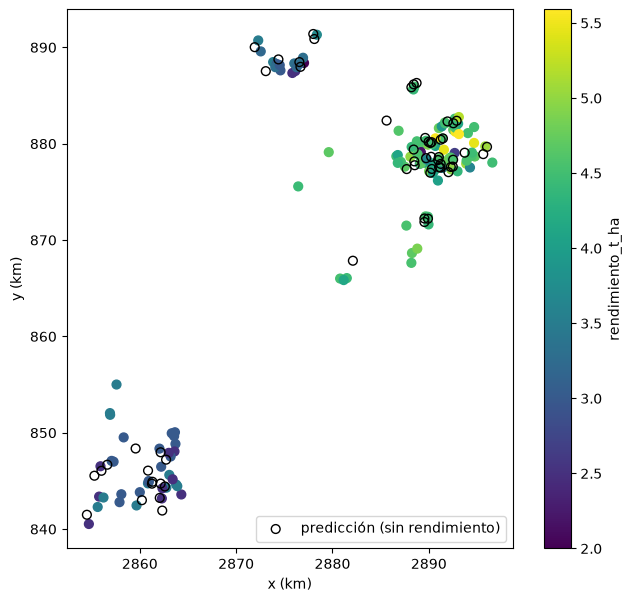

In [47]:
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(train["x_m"] / 1000, train["y_m"] / 1000, c=train[target], cmap="viridis", s=40)
ax.scatter(prueba["x_m"] / 1000, prueba["y_m"] / 1000, facecolors="none", edgecolors="k", s=40, label="predicción (sin rendimiento)")
plt.colorbar(sc, label=target)
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_aspect("equal"); ax.legend()
plt.show()

## Limpiar Datos

- Las variables `n_validos` miden nubes y órbita del satélite, no la parcela, y funcionan como indicador de ubicación: se descartan.
- Tmax casi no varía, la amplitud térmica es ≈ −Tmin y las ventanas de tiempo se repiten: se conserva Tmin y precipitación de abril a octubre (el ciclo del cultivo).
- Los índices de vegetación están muy correlacionados entre sí y entre sensores: se conserva una variable por grupo de redundancia.
- Las coordenadas no mejoraron la predicción respecto al municipio (parte 4), así que no se incluyen.
- El municipio explica casi todo lo que hay que explicar (RMSE 0.513 vs 0.855 con la media global): se incluye codificado.

In [7]:
RUTA_ENTRADA = "../Dataset/NewDataset/dataset_modelo_cebada.csv"
CARPETA_SALIDA = Path("../Dataset/NewDataset")
META = ["ID_POLIGON", "CONJUNTO", "Municipio"]

INCLUIR_PLANET = True        # False: solo Sentinel-2
INCLUIR_LANDSAT = False      # solo aporta vi6t, con huecos; sin evidencia de aportar nada
UMBRAL_REDUNDANCIA = 0.95    # |rho de Spearman| a partir del cual dos variables se consideran la misma
UMBRAL_COBERTURA = 50        # % mínimo de la parcela cubierta por el raster para confiar en elevación/pendiente

df = pd.read_csv(RUTA_ENTRADA)

assert len(df) == 197 and df["ID_POLIGON"].is_unique


print(df.shape, df["CONJUNTO"].value_counts().to_dict())

(197, 103) {'ENTRENAMIENTO': 138, 'PREDICCION': 59}


In [8]:
cols_num = [c for c in df.select_dtypes("number").columns if c != target]
descartes = {}   # columna -> (motivo, reemplazada_por)

def descartar(cols, motivo, por=None):
    for c in cols:
        descartes[c] = (motivo, por)

# Calidad satelital
descartar([c for c in cols_num if "n_validos" in c],
          "Cuenta de observaciones útiles: depende de nubes y órbita, no de la parcela (indicador de ubicación)")

# Topografía: se anula el dato donde el raster cubre poco la parcela y se descarta el control de calidad
for cobertura, valor in [("cobertura_elevacion_pct", "elevacion_media"), ("cobertura_pendiente_pct", "pendiente_media")]:
    bajo = df[cobertura] < UMBRAL_COBERTURA
    print(f"{valor}: se anula en {bajo.sum()} parcelas con cobertura < {UMBRAL_COBERTURA} %")
    df.loc[bajo, valor] = np.nan
descartar(["cobertura_elevacion_pct", "cobertura_pendiente_pct", "pendiente_baja_cobertura"],
          "Control de calidad del raster, no característica de la parcela (ya se usó para anular datos poco confiables)")

# Clima: se conserva Tmin y precipitación de abril a octubre
descartar([c for c in cols_num if c.startswith("Tmax")],
          "Casi constante entre parcelas (desviación de 0.12 a 0.17 °C)")
descartar([c for c in cols_num if c.startswith("amplitud")],
          "Equivale a -Tmin (rho ≈ -0.99): misma información", "Tmin_media_abril_octubre")
descartar([c for c in cols_num if c.startswith(("Tmin", "precipitacion")) and not c.endswith("abril_octubre")],
          "Ventana de tiempo redundante; se conserva la de abril-octubre (ciclo del cultivo)")

# Sensores excluidos por configuración
if not INCLUIR_PLANET:
    descartar([c for c in cols_num if c.startswith("pl_") and c not in descartes], "Excluida por configuración (INCLUIR_PLANET=False)")
if not INCLUIR_LANDSAT:
    descartar([c for c in cols_num if c.startswith("ls_") and c not in descartes], "Excluida por configuración (INCLUIR_LANDSAT=False)")

print("Descartadas hasta ahora:", len(descartes), "de", len(cols_num))

elevacion_media: se anula en 0 parcelas con cobertura < 50 %
pendiente_media: se anula en 2 parcelas con cobertura < 50 %
Descartadas hasta ahora: 35 de 99


In [9]:
ORDEN_SENSOR = {"s2_": 0, "pl_": 1, "ls_": 2}
ORDEN_INDICE = ["ndvi", "evi", "msavi", "lai", "fapar", "ndwi", "msi", "vi6t"]
ORDEN_STAT = ["media", "max", "auc", "doy_max", "std"]

def prioridad(c):
    partes = c.split("_")
    indice = partes[1]
    resto = "_".join(partes[2:])
    if resto.startswith("mes_"):
        stat = 10 + int(resto[-2:])
    else:
        stat = ORDEN_STAT.index(resto) if resto in ORDEN_STAT else 99
    return (ORDEN_SENSOR[c[:3]], ORDEN_INDICE.index(indice) if indice in ORDEN_INDICE else 99, stat)


sat = sorted([c for c in cols_num if c.startswith(tuple(ORDEN_SENSOR)) and c not in descartes], key=prioridad)
corr = df[sat].corr(method="spearman").abs()

conservadas = []
for c in sat:
    rep = next((q for q in conservadas if corr.loc[c, q] > UMBRAL_REDUNDANCIA), None)
    if rep is None:
        conservadas.append(c)
    else:
        descartes[c] = (f"Redundante: |rho| > {UMBRAL_REDUNDANCIA} con una variable ya conservada", rep)

print(f"Satelitales: {len(sat)} candidatas -> {len(conservadas)} conservadas")
print(conservadas)

Satelitales: 59 candidatas -> 47 conservadas
['s2_ndvi_media', 's2_ndvi_max', 's2_ndvi_auc', 's2_ndvi_doy_max', 's2_ndvi_std', 's2_ndvi_mes_04', 's2_ndvi_mes_05', 's2_ndvi_mes_06', 's2_ndvi_mes_07', 's2_ndvi_mes_08', 's2_ndvi_mes_09', 's2_ndvi_mes_10', 's2_evi_media', 's2_evi_max', 's2_evi_auc', 's2_evi_doy_max', 's2_evi_std', 's2_lai_doy_max', 's2_ndwi_media', 's2_ndwi_max', 's2_ndwi_auc', 's2_ndwi_doy_max', 's2_ndwi_std', 's2_msi_max', 's2_msi_doy_max', 's2_msi_std', 'pl_ndvi_media', 'pl_ndvi_max', 'pl_ndvi_auc', 'pl_ndvi_doy_max', 'pl_ndvi_std', 'pl_ndvi_mes_04', 'pl_ndvi_mes_05', 'pl_ndvi_mes_06', 'pl_ndvi_mes_07', 'pl_ndvi_mes_09', 'pl_evi_media', 'pl_evi_max', 'pl_evi_auc', 'pl_evi_doy_max', 'pl_evi_std', 'pl_msavi_max', 'pl_msavi_doy_max', 'pl_lai_max', 'pl_lai_auc', 'pl_lai_doy_max', 'pl_lai_std']


In [10]:
features_num = [c for c in cols_num if c not in descartes]

# Municipio -> columnas 0/1 (las categorías se fijan con los 197 datos; no depende del rendimiento)
dummies = pd.get_dummies(df["Municipio"].str.replace(" ", "_"), prefix="mun", dtype=int)
final = pd.concat([df[META + [target] + features_num], dummies], axis=1)
features = features_num + list(dummies.columns)

train_f = final[final["CONJUNTO"] == "ENTRENAMIENTO"].reset_index(drop=True)
pred_f = final[final["CONJUNTO"] == "PREDICCION"].drop(columns=target).reset_index(drop=True)

CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
train_f.to_csv(CARPETA_SALIDA / "dataset_final_entrenamiento.csv", index=False)
pred_f.to_csv(CARPETA_SALIDA / "dataset_final_prediccion.csv", index=False)


def grupo(c):
    if "n_validos" in c: return "calidad_satelital"
    if c.startswith("s2_"): return "satelital_s2"
    if c.startswith("pl_"): return "satelital_planet"
    if c.startswith("ls_"): return "satelital_landsat"
    if c.startswith(("precipitacion", "Tmax", "Tmin", "amplitud")): return "clima"
    if c.startswith(("elevacion", "pendiente", "cobertura")): return "topografia"
    return "otro"

filas = []
for c in cols_num:
    motivo, por = descartes.get(c, ("", None))
    filas.append({"columna": c, "grupo": grupo(c), "estado": "descartada" if c in descartes else "conservada",
                  "motivo": motivo, "reemplazada_por": por})
for c in dummies.columns:
    filas.append({"columna": c, "grupo": "municipio", "estado": "creada", "motivo": "Municipio codificado 0/1", "reemplazada_por": None})
diccionario = pd.DataFrame(filas)
diccionario.to_csv(CARPETA_SALIDA / "diccionario_columnas.csv", index=False)

print(f"Entrenamiento: {train_f.shape} | Predicción: {pred_f.shape} | Variables para el modelo: {len(features)}")
print(diccionario.groupby(["grupo", "estado"]).size().unstack(fill_value=0))

Entrenamiento: (138, 65) | Predicción: (59, 64) | Variables para el modelo: 61
estado             conservada  creada  descartada
grupo                                            
calidad_satelital           0       0          10
clima                       2       0          10
municipio                   0       9           0
otro                        1       0           0
satelital_landsat           0       0          12
satelital_planet           21       0           6
satelital_s2               26       0           6
topografia                  2       0           3
